In [1]:
"""
Training script for Per-Alternative DS-CI Probit Emulator.
"""

import random
import numpy as np
import torch
import torch.optim as optim
from emulator import Emulator
from training import train_model, load_checkpoint, InverseSqrtScheduler
from utils import get_device

def set_seed(seed=42):
    """Set all random seeds for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = get_device()
def train(k, emulator_config, lambda_grad=1e-4, seed=42):
    set_seed(seed)
    model = Emulator(name="emulator", **emulator_config).to(device)
    
    # ============================================================================
    # Print model summary
    # ============================================================================
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"\nModel: {model.name}")
    print(f"Total parameters: {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,}")
    print(f"Config: {emulator_config}")
    
    # ============================================================================
    # Optimizer configuration
    # ============================================================================
    optimizer = optim.AdamW(model.parameters(), lr=0.003, betas=(0.9, 0.999), eps=1e-8, weight_decay=3e-6)
    scheduler = InverseSqrtScheduler(optimizer, warmup_steps=5000, min_lr_ratio=0.)
    
    # ============================================================================
    # Training configuration
    # ============================================================================
    num_epochs = 400_000
    num_samples = 1_000_000
    batch_size = 10_000
    eval_batch_size = 10_000
    eval_every = 200
    
    # Replay buffer configuration
    buffer_size = 400_000
    buffer_add_per_step = None
    buffer_add_every = None
    
    # Sobolev training configuration
    tau = 5.  # Temperature for soft gradient computation
    
    # ============================================================================
    # Train
    # ============================================================================
    model, df = train_model(
        model, k, optimizer, num_epochs, batch_size, num_samples,
        eval_every, eval_batch_size, plot=True, scheduler=scheduler, 
        buffer_size=buffer_size, buffer_add_per_step=buffer_add_per_step, 
        buffer_add_every=buffer_add_every, lambda_grad=lambda_grad, tau=tau)

    return model, df

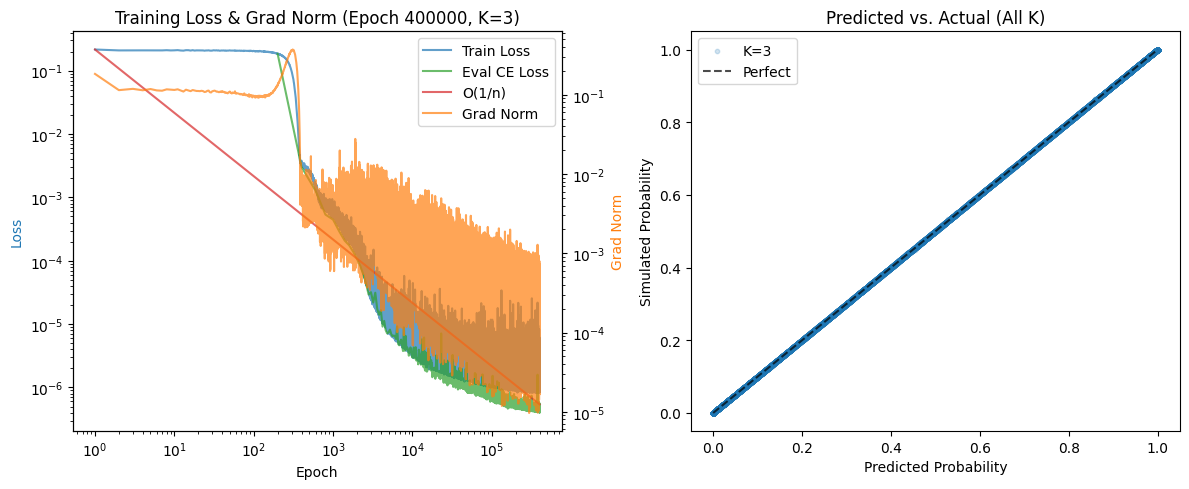

100%|███████████████████████████████████████████████████████████████████████████████████████| 400000/400000 [2:49:17<00:00,  6.51it/s]

100%|███████████████████████████████████████████████████████████████████████████████████████| 400000/400000 [2:49:17<00:00, 39.38it/s]


CPU Forward Pass Timing (batch_size=10000, K=3):
  Current:  5.60 ms total, 0.56 µs/sample
  Average:  5.64 ms total, 0.56 µs/sample
  Optimizer: AdamW
  Training on K values: [3]
    K=3: Train buffer=400000, Eval buffer=40000
  Directional derivative training: lambda_grad=0.0001, num_directions=1, epsilon=1e-05
  Last train CE loss: 0.000001, grad loss: 0.006427


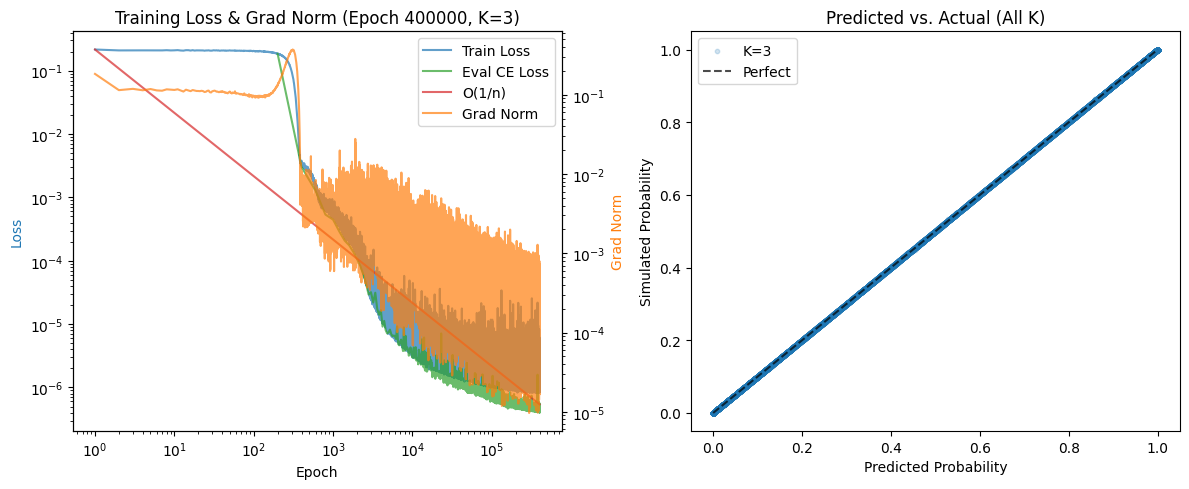

In [2]:
k = 3

# Emulator parameters
emulator_config = {
    # Diagonal DeepSet
    'diag_phi_hidden_dim': 8,
    'diag_phi_output_dim': 8,
    'diag_phi_num_layers': 0,
    'diag_rho_hidden_dim': 8,
    'diag_rho_output_dim': 8,
    'diag_rho_num_layers': 0,
    # Off-diagonal DeepSet
    'offdiag_phi_hidden_dim': 8,
    'offdiag_phi_output_dim': 8,
    'offdiag_phi_num_layers': 0,
    'offdiag_rho_hidden_dim': 8,
    'offdiag_rho_output_dim': 8,
    'offdiag_rho_num_layers': 0,
    # Combining MLP
    'combine_hidden_dim': 12,
    'combine_output_dim': 8,
    'combine_num_layers': 2,
    # Equivariant layers
    'equiv_hidden_dim': 4,
    'num_equiv_layers': 1,
    # Shared
    'dropout_rate': 0.1
}

model3, df3 = train(k, emulator_config, lambda_grad=1e-4)

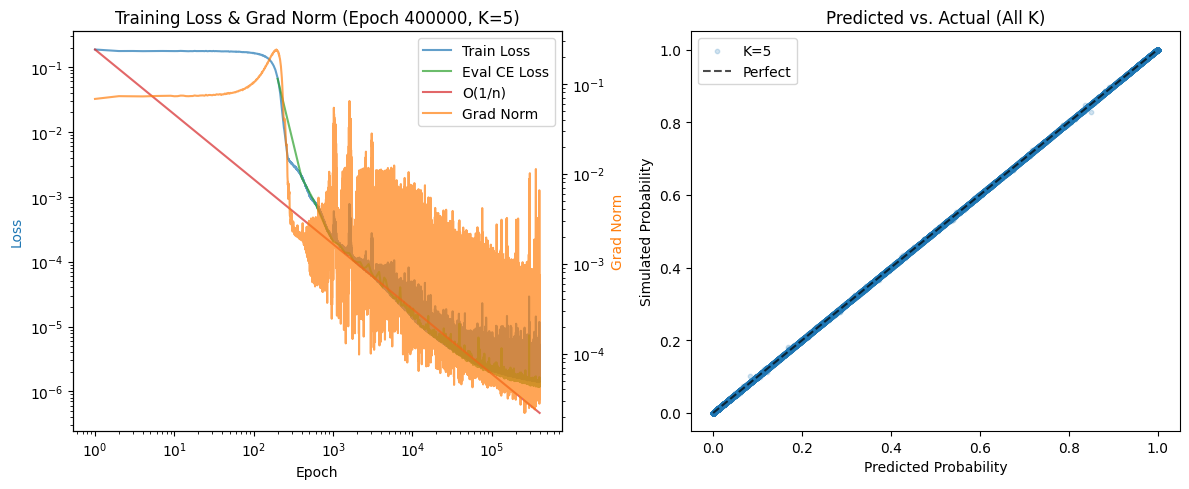

100%|███████████████████████████████████████████████████████████████████████████████████████| 400000/400000 [4:50:57<00:00, 22.91it/s]


CPU Forward Pass Timing (batch_size=10000, K=5):
  Current:  11.74 ms total, 1.17 µs/sample
  Average:  12.68 ms total, 1.27 µs/sample
  Optimizer: AdamW
  Training on K values: [5]
    K=5: Train buffer=400000, Eval buffer=40000
  Directional derivative training: lambda_grad=0.0001, num_directions=1, epsilon=1e-05
  Last train CE loss: 0.000001, grad loss: 0.004047


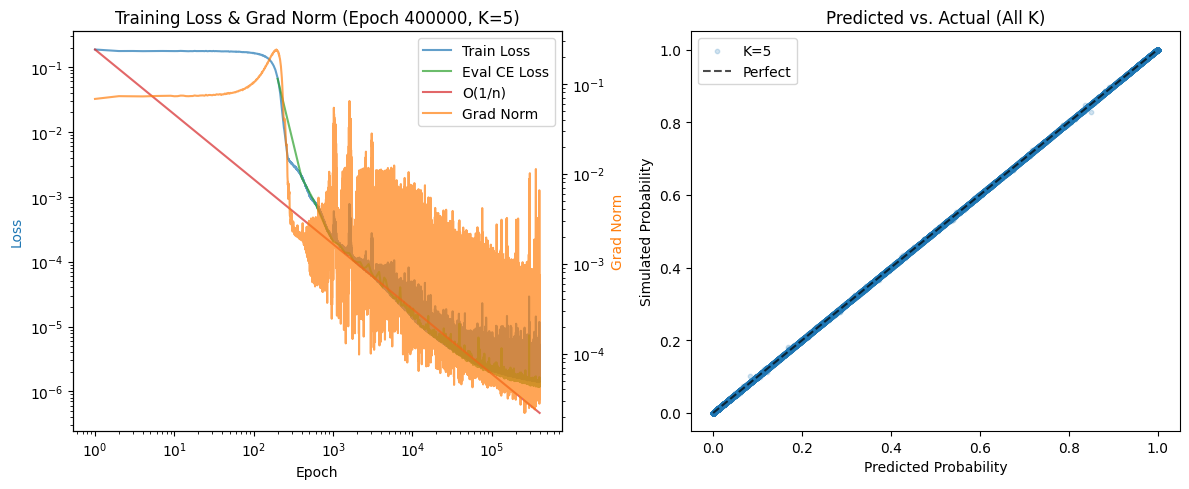

In [3]:
k = 5

# Emulator parameters
emulator_config = {
    # Diagonal DeepSet
    'diag_phi_hidden_dim': 24,
    'diag_phi_output_dim': 24,
    'diag_phi_num_layers': 1,
    'diag_rho_hidden_dim': 24,
    'diag_rho_output_dim': 24,
    'diag_rho_num_layers': 0,
    # Off-diagonal DeepSet
    'offdiag_phi_hidden_dim': 24,
    'offdiag_phi_output_dim': 24,
    'offdiag_phi_num_layers': 1,
    'offdiag_rho_hidden_dim': 24,
    'offdiag_rho_output_dim': 24,
    'offdiag_rho_num_layers': 0,
    # Combining MLP
    'combine_hidden_dim': 48,
    'combine_output_dim': 24,
    'combine_num_layers': 2,
    # Equivariant layers
    'equiv_hidden_dim': 12,
    'num_equiv_layers': 1,
    # Shared
    'dropout_rate': 0.1
}

model5, df5 = train(k, emulator_config, lambda_grad=1e-4)

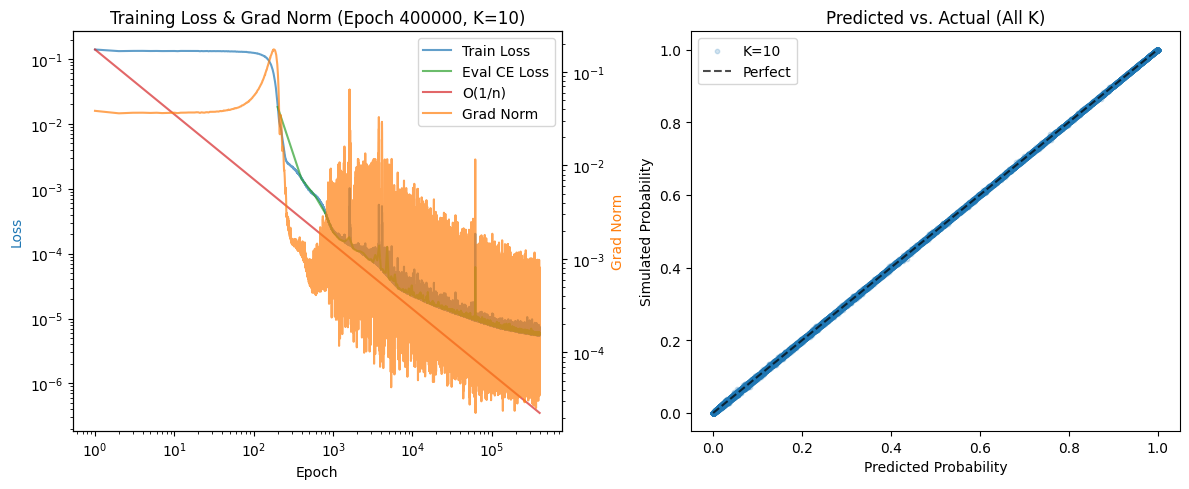

100%|██████████████████████████████████████████████████████████████████████████████████████| 400000/400000 [13:57:01<00:00,  1.14s/it]

100%|██████████████████████████████████████████████████████████████████████████████████████| 400000/400000 [13:57:01<00:00,  7.96it/s]


CPU Forward Pass Timing (batch_size=10000, K=10):
  Current:  30.42 ms total, 3.04 µs/sample
  Average:  29.43 ms total, 2.94 µs/sample
  Optimizer: AdamW
  Training on K values: [10]
    K=10: Train buffer=400000, Eval buffer=40000
  Directional derivative training: lambda_grad=0.0001, num_directions=1, epsilon=1e-05
  Last train CE loss: 0.000006, grad loss: 0.001333


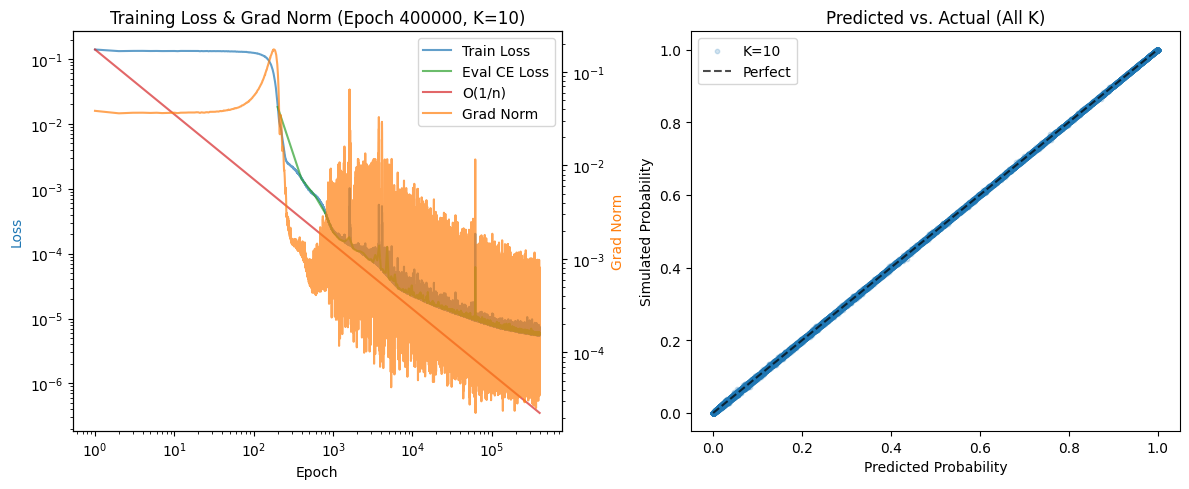

In [4]:
k = 10

# Emulator parameters
emulator_config = {
    # Diagonal DeepSet
    'diag_phi_hidden_dim': 32,
    'diag_phi_output_dim': 32,
    'diag_phi_num_layers': 1,
    'diag_rho_hidden_dim': 32,
    'diag_rho_output_dim': 32,
    'diag_rho_num_layers': 0,
    # Off-diagonal DeepSet
    'offdiag_phi_hidden_dim': 32,
    'offdiag_phi_output_dim': 32,
    'offdiag_phi_num_layers': 1,
    'offdiag_rho_hidden_dim': 32,
    'offdiag_rho_output_dim': 32,
    'offdiag_rho_num_layers': 0,
    # Combining MLP
    'combine_hidden_dim': 64,
    'combine_output_dim': 32,
    'combine_num_layers': 2,
    # Equivariant layers
    'equiv_hidden_dim': 16,
    'num_equiv_layers': 1,
    # Shared
    'dropout_rate': 0.1
}

model10, df10 = train(k, emulator_config, lambda_grad=1e-4)